# Part 4 of 5: Robustness, Background Bias & Countermeasure

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 13–14: robustness of the final models on the same test leaves, the same leaf on different backgrounds, where the models look, and training with random backgrounds as a countermeasure.

The notebooks run in order: `01_data` → `02_models_and_tuning` → `03_test_evaluation` → `04_background_bias` → `05_generalisation`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay
from torchvision.utils import make_grid

from plantdisease.backgrounds import add_background_tests, make_test_variants, stripes
from plantdisease.config import CFG, SEEDS, SHORT_NAMES, out_path
from plantdisease.data import make_loader, prepare
from plantdisease.evaluate import (
    bootstrap_f1,
    bootstrap_resamples,
    leaf_group_members,
    leaf_share_table,
    macro_f1,
    paired_difference,
    seed_range,
    verdict,
)
from plantdisease.experiments import countermeasure_names, load_final_models
from plantdisease.plots import finish, grouped_bars
from plantdisease.train import load_history, predict_labels, run_seeds, train_dataset

# selected on the validation set (notebook 02)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 13. Robustness & Background Bias

PlantVillage photos are taken under controlled conditions: one leaf, a plain background and even lighting. Real field photos are not. We evaluate every final model and seed on **the same test leaves** under these transformations:

| Test variant | Question |
|---|---|
| **background removed** (PlantVillage `raw/segmented`, leaf on black) | Does the model rely on the leaf or on the background? Every class comes from its own photo series with its own background (Section 4), so a model can learn the background instead of the leaf and then fail on leaves without it. |
| **grayscale** | How much does the model rely on colour (e.g. yellowing) versus lesion shape/texture? |
| **darker (×0.6)** | Robustness to poor lighting |
| **blur (Gaussian, σ = 2)** | Robustness to out-of-focus photos |
| **noise (σ = 20 grey levels)** | Robustness to sensor noise / low light |

None of these variants was seen during training of the models of Sections 7 to 10, so a drop measures generalisation beyond the training conditions. Grayscale, darker, blur and noise ask about colour and image quality; the background question runs through the sections that follow: the table above shows whether there is a problem, Section 13.2 changes only the background of the same leaf, Section 13.3 shows where the models look, Section 14 tests a countermeasure and Section 15 tests photo series that were left out of training.


Test images with a segmented version: 892 / 892


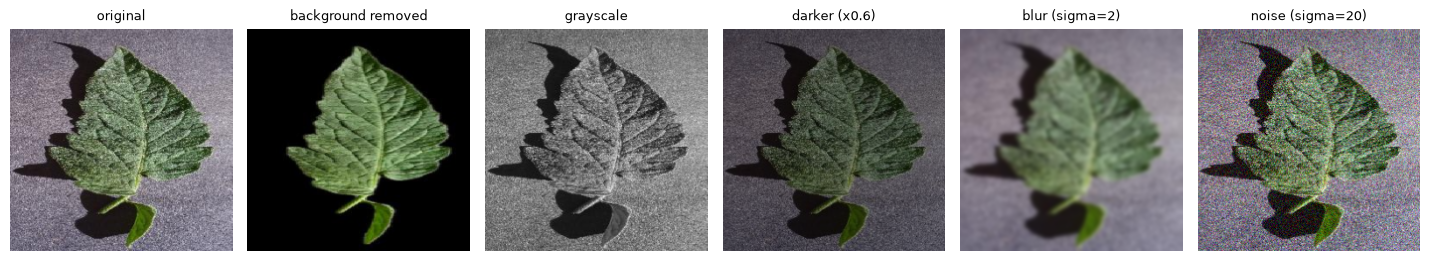

In [26]:
# Test leaves with a segmented version, under every condition (plantdisease/backgrounds.py: make_test_variants)
tv = make_test_variants(data)
VARIANTS, y_rob = tv.variants, tv.y

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(2.4 * len(VARIANTS), 2.6))
for ax, (variant, imgs) in zip(axes, VARIANTS.items(), strict=True):
    ax.imshow(imgs[0].permute(1, 2, 0))
    ax.set_title(variant, fontsize=9)
    ax.axis("off")
finish()

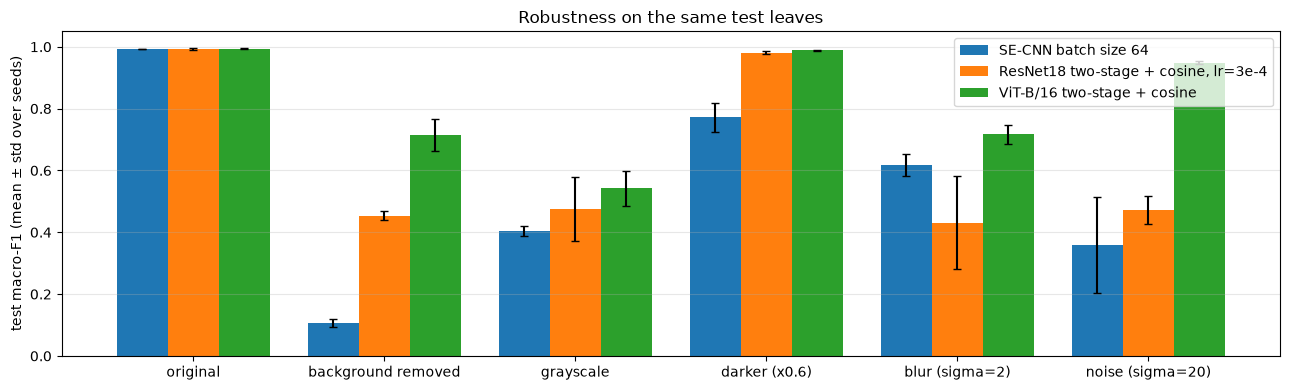

variant,original,background removed,grayscale,darker (x0.6),blur (sigma=2),noise (sigma=20)
model,,,,,,
SE-CNN batch size 64,0.993,0.106,0.404,0.772,0.617,0.359
"ResNet18 two-stage + cosine, lr=3e-4",0.993,0.454,0.475,0.981,0.431,0.472
ViT-B/16 two-stage + cosine,0.994,0.714,0.542,0.988,0.717,0.949


In [27]:
# (model, seed, condition) -> predicted classes
rob_preds = predict_labels(FINAL_MODELS, VARIANTS)
robust = pd.DataFrame(
    [
        {
            "model": name,
            "seed": seed,
            "variant": variant,
            "macro_f1": macro_f1(y_rob, preds),
        }
        for (name, seed, variant), preds in rob_preds.items()
    ]
)
robust.to_csv(out_path("robustness_per_seed.csv"), index=False)

# dropna=False: keep the std columns even with a single seed (all NaN)
rob_mean, rob_std = (
    robust.pivot_table(
        index="model", columns="variant", values="macro_f1", aggfunc=agg, dropna=False
    ).loc[FINAL_MODELS, list(VARIANTS)]
    for agg in ("mean", "std")
)

fig, ax = plt.subplots(figsize=(13, 4))
grouped_bars(
    ax,
    list(VARIANTS),
    FINAL_MODELS,
    [rob_mean.loc[n] for n in FINAL_MODELS],
    yerr=[rob_std.loc[n] for n in FINAL_MODELS],
)
ax.set_ylabel("test macro-F1 (mean ± std over seeds)")
ax.set_ylim(0, 1.05)
ax.set_title("Robustness on the same test leaves")
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
finish("robustness.png")
rob_mean.round(3)

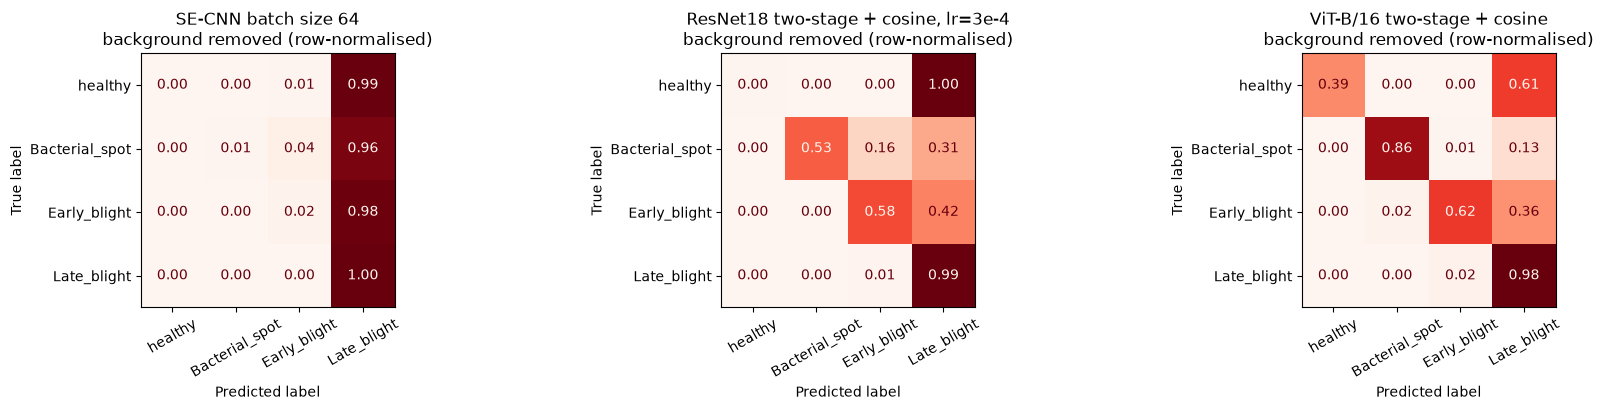

In [28]:
# Background shortcut: share of predictions per class when the background is removed (seeds pooled)
fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 4.2))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    preds = np.concatenate([rob_preds[(name, s, "background removed")] for s in SEEDS])
    ConfusionMatrixDisplay.from_predictions(
        np.tile(y_rob, len(SEEDS)),
        preds,
        display_labels=SHORT_NAMES,
        normalize="true",
        values_format=".2f",
        cmap="Reds",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name}\nbackground removed (row-normalised)")
finish("background_removed_confusion.png")

### 13.1 Robustness with uncertainty

The robustness scores vary for two reasons: **which leaves** are in the test set (bootstrap, as in Section 10.1) and **which seed** trained the model. Under distribution shift the second reason is much larger (for example about 0.15 standard deviation over seeds for the CNN under noise), and the bootstrap does not see it. We therefore show both. The bars are the mean over seeds with the bootstrap interval, the dots are the three individual seeds.

A model is called **clearly better** than another only if every seed of the first beats every seed of the second **and** the paired bootstrap interval lies above 0. If the seed ranges overlap we only speak of a tendency.

In [16]:
ROB_RESAMPLES = bootstrap_resamples(leaf_group_members(tv.groups))
boot_rob = {}  # (model, variant) -> macro-F1 of every resample
seed_scores = {}  # (model, variant) -> macro-F1 of each training seed
rows = []
for name in FINAL_MODELS:
    for variant in VARIANTS:
        preds = [rob_preds[(name, seed, variant)] for seed in SEEDS]
        scores = seed_scores[(name, variant)] = np.array(
            [macro_f1(y_rob, p) for p in preds]
        )
        boot_rob[(name, variant)] = bootstrap_f1(preds, y_rob, ROB_RESAMPLES)
        low, high = np.percentile(boot_rob[(name, variant)], [2.5, 97.5])
        rows.append(
            {
                "model": name,
                "variant": variant,
                "macro_f1": scores.mean(),
                "low": low,
                "high": high,
                "seed_min": scores.min(),
                "seed_max": scores.max(),
                "text": f"{scores.mean():.3f} [{low:.3f}, {high:.3f}], seeds {seed_range(scores)}",
            }
        )
rob_ci = pd.DataFrame(rows)
rob_ci.drop(columns="text").to_csv(out_path("robustness_intervals.csv"), index=False)

sub = {
    n: rob_ci[rob_ci.model == n].set_index("variant").loc[list(VARIANTS)]
    for n in FINAL_MODELS
}
fig, ax = plt.subplots(figsize=(13, 4))
grouped_bars(
    ax,
    list(VARIANTS),
    FINAL_MODELS,
    [sub[n]["macro_f1"] for n in FINAL_MODELS],
    yerr=[
        [sub[n]["macro_f1"] - sub[n]["low"], sub[n]["high"] - sub[n]["macro_f1"]]
        for n in FINAL_MODELS
    ],
    seeds=[[seed_scores[(n, v)] for v in VARIANTS] for n in FINAL_MODELS],
    jitter=True,
    dot_size=10,
    alpha=0.8,
)
ax.set_ylabel("test macro-F1 (bar: mean, interval: test leaves; dots: seeds)")
ax.set_ylim(0, 1.05)
ax.set_title("Robustness: uncertainty from the test leaves and from the training seed")
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
finish("robustness_intervals.png")
rob_ci.pivot(index="model", columns="variant", values="text").loc[
    FINAL_MODELS, list(VARIANTS)
]

NameError: name 'bootstrap_resamples' is not defined

In [ ]:
rows = []
for i, name_a in enumerate(FINAL_MODELS):
    for name_b in FINAL_MODELS[i + 1 :]:
        # the clean test was compared in Section 10.2
        for variant in list(VARIANTS)[1:]:
            seeds_a, seeds_b = (
                seed_scores[(name_a, variant)],
                seed_scores[(name_b, variant)],
            )
            diff, low, high, result = verdict(
                boot_rob[(name_a, variant)],
                boot_rob[(name_b, variant)],
                seeds_a,
                seeds_b,
                names=(name_a, name_b),
            )
            rows.append(
                {
                    "model A": name_a,
                    "model B": name_b,
                    "condition": variant,
                    "A - B": diff,
                    "95% interval (test leaves)": f"[{low:+.3f}, {high:+.3f}]",
                    "seeds A": seed_range(seeds_a),
                    "seeds B": seed_range(seeds_b),
                    "verdict": result,
                }
            )
paired_shift = pd.DataFrame(rows)
paired_shift.to_csv(out_path("paired_comparison_shift.csv"), index=False)
paired_shift.round(3)

### 13.2 Is it the background? The same leaf on two backgrounds

Removing the background changes more than the background: black pixels and a sharp mask edge appear, and the segmentation sometimes cuts away the thin edge of the leaf. Here **only the background changes**. We take the leaf of every test photo (the **leaf mask** is every pixel that is not black in the segmented photo, small gaps closed, holes filled) and place it on a background tile:

| Test variant | Background | Question |
|---|---|---|
| **same-class background** | corner of another test photo of the **same class** | Control: the same cut-out leaf with a background that fits its label. |
| **other-class background** | corner of a test photo of a **different class** | Do the predictions follow the leaf or the background? |

Both versions contain exactly the same leaf pixels, so a difference between them can only come from the background. A model that learned the background predicts the class of the background photo in the second version. The tile is a 32 × 32 corner of another test photo without leaf pixels, mirrored and repeated over the image. We report macro-F1 as in Section 13.1 and the **share of predictions that equal the class of the background photo**.

Leaf masks, corner tiles and the composed images are built by `add_background_tests` in `plantdisease/backgrounds.py`.

In [ ]:
# adds tv.masks, tv.keep, tv.background_tests and tv.donor_class
add_background_tests(tv)
BACKGROUND_TESTS, DONOR_CLASS = tv.background_tests, tv.donor_class

# Examples: original photo, same leaf on a background of its own class, on a background of another class
fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
for col, i in enumerate(np.linspace(0, len(y_rob) - 1, 6).astype(int)):
    for row, (title, imgs) in enumerate(
        {"original": tv.original, **BACKGROUND_TESTS}.items()
    ):
        axes[row, col].imshow(imgs[i].permute(1, 2, 0))
        axes[row, col].set_title(f"{SHORT_NAMES[y_rob[i]]}\n{title}", fontsize=8)
        axes[row, col].axis("off")
finish()

In [ ]:
bg_preds = predict_labels(FINAL_MODELS, BACKGROUND_TESTS)
bg_boot, rows = {}, []
for name in FINAL_MODELS:
    for variant in BACKGROUND_TESTS:
        preds = [bg_preds[(name, seed, variant)] for seed in SEEDS]
        scores = seed_scores[(name, variant)] = np.array(
            [macro_f1(y_rob, p) for p in preds]
        )
        bg_boot[(name, variant)] = bootstrap_f1(preds, y_rob, ROB_RESAMPLES)
        low, high = np.percentile(bg_boot[(name, variant)], [2.5, 97.5])
        follows = np.mean([(p == DONOR_CLASS[variant]).mean() for p in preds])
        rows.append(
            {
                "model": name,
                "variant": variant,
                "macro_f1": scores.mean(),
                "95% interval (test leaves)": f"[{low:.3f}, {high:.3f}]",
                "seeds": seed_range(scores),
                "prediction = class of the background photo": (
                    follows if variant == "other-class background" else np.nan
                ),
            }
        )
background_tests = pd.DataFrame(rows)
background_tests.to_csv(out_path("background_swap_tests.csv"), index=False)

conditions = ["original", *BACKGROUND_TESTS]
fig, ax = plt.subplots(figsize=(8, 3.8))
grouped_bars(
    ax,
    FINAL_MODELS,
    conditions,
    [[seed_scores[(n, c)].mean() for n in FINAL_MODELS] for c in conditions],
    seeds=[[seed_scores[(n, c)] for n in FINAL_MODELS] for c in conditions],
)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylabel("test macro-F1 (bars: mean, dots: seeds)")
ax.set_ylim(0, 1.05)
ax.set_title("The same leaves on a background of their own class and of another class")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", alpha=0.3)
finish("background_swap_tests.png")
background_tests.round(3)

In [ ]:
# Same leaf, only the background differs: other-class minus same-class background
rows = []
donor = DONOR_CLASS["other-class background"]
for name in FINAL_MODELS:
    diff, low, high = paired_difference(
        bg_boot[(name, "other-class background")],
        bg_boot[(name, "same-class background")],
    )
    row = {
        "model": name,
        "other - same (macro-F1)": diff,
        "95% interval (test leaves)": f"[{low:+.3f}, {high:+.3f}]",
    }
    for c, short in enumerate(SHORT_NAMES):  # which background pulls the prediction?
        follows = [
            (bg_preds[(name, s, "other-class background")][donor == c] == c).mean()
            for s in SEEDS
        ]
        row[f"follows a {short} background"] = np.mean(follows)
    rows.append(row)
same_vs_other = pd.DataFrame(rows).set_index("model")
same_vs_other.to_csv(out_path("background_swap_paired.csv"))
same_vs_other.round(3)

### 13.3 Where do the models look? Attention on the leaf

Section 12.2 showed Grad-CAM maps for six example photos. Here we turn them into one number per model. From the **leaf mask** of Section 13.2 (taken from the segmented photo of the same leaf) we compute the **leaf share**: the part of the Grad-CAM weight that lies on the leaf. A map that ignored the leaf would give the leaf's share of the image area (*leaf area share*), so a model that really looks at the leaf has a leaf share clearly above that value.

We compute it for the original photos, for the photos with the background removed (the condition in which the shortcut appeared in Section 13) and for the same leaves on the background of another class (Section 13.2). Grad-CAM needs convolutional feature maps, so the ViT is not included.

Grad-CAM and the leaf share are computed by `leaf_attention` and `leaf_share_table` in `plantdisease/evaluate.py`.

In [ ]:
leaf_attention_table = leaf_share_table([BEST_CNN, BEST_RESNET], tv.all_tests, tv.masks)
leaf_attention_table.to_csv(out_path("leaf_attention.csv"))

fig, ax = plt.subplots(figsize=(8, 3.8))
positions = np.arange(len(leaf_attention_table))
ax.bar(
    positions,
    leaf_attention_table["leaf share"],
    yerr=[
        leaf_attention_table["leaf share"] - leaf_attention_table["seed min"],
        leaf_attention_table["seed max"] - leaf_attention_table["leaf share"],
    ],
    capsize=3,
    label="leaf share of the attention (mean, seed range)",
)
ax.scatter(
    positions,
    leaf_attention_table["leaf area share"],
    marker="_",
    s=900,
    color="red",
    label="leaf area share (uniform map)",
)
ax.set_xticks(
    positions, [f"{n}\n{c}" for n, c in leaf_attention_table.index], fontsize=8
)
ax.set_ylim(0, 1)
ax.set_ylabel("share of the Grad-CAM weight on the leaf")
ax.set_title("Where do the models look?")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", alpha=0.3)
finish("leaf_attention.png")
leaf_attention_table.round(3)

## 14. Countermeasure: Training with Random Backgrounds

Section 13 tests whether the models rely on the photo background. Every class comes from its own photo series (Section 4), so in the training data the background carries information about the label. As a countermeasure, **the background behind the leaf is replaced by a random one during training**:

| Model | Training | Purpose |
|---|---|---|
| **baseline** | unchanged | reference |
| **countermeasure** | with probability 0.5 everything outside the leaf mask becomes black, a solid colour, a gradient, smooth noise or a leaf-free corner tile of another training photo | the background no longer tells the class |
| **control** | the same cut-out leaves, but the background tile always comes from a photo of the same class | separates label-free backgrounds from seeing cut-out leaves |

The leaf masks come from the segmented photos (Section 13.2); photos with an empty or missing mask stay unchanged. The swap is an additional augmentation before the usual ones. The selected CNN and ResNet18 keep all hyper-parameters, the split, the seeds and the checkpoint selection (clean validation macro-F1). The tests are those of Section 13.2, background removed and diagonal stripes, a background type that never occurs in training. Black is a training background, so "background removed" is not unseen for the countermeasure models.


### 14.1 Leaf masks and the background augmentation

A configuration can carry two optional settings, `background_swap` (the swap probability) and `class_matched_background`. With them, `train_dataset` (`plantdisease/train.py`) uses `BackgroundSwapDataset` (`plantdisease/backgrounds.py`) for training; without them nothing changes.


In [ ]:
# leaf masks of all photos, aligned with data.images
LEAF_MASKS, SWAP_OK = data.swap_masks

# Visualise training images with random backgrounds
swap = {"augment": True, "background_swap": CFG["countermeasure"]["swap_prob"]}
x, y = next(iter(make_loader(train_dataset(swap, data), 16, seed=0)))
plt.figure(figsize=(12, 3.5))
plt.imshow(make_grid(x, nrow=8, padding=2, normalize=True).permute(1, 2, 0))
plt.axis("off")
plt.title("Random backgrounds: " + ", ".join(SHORT_NAMES[c] for c in y[:8]) + ", ...")
plt.show()

### 14.2 Training the countermeasure models

Each selected model is trained twice more with all training seeds: with **random backgrounds** (the countermeasure) and with **class-matched backgrounds** (the control).


In [ ]:
# '<model> + random backgrounds' and '<model> + class-matched backgrounds' (plantdisease/experiments.py: config_of)
countermeasure_models = [
    name for base in (BEST_CNN, BEST_RESNET) for name in countermeasure_names(base)
]
for name in countermeasure_models:
    run_seeds(name, data)

In [ ]:
# Validation curves of the baselines, countermeasures and controls (thin: seeds, thick: mean)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex="col")
for col, base in enumerate((BEST_CNN, BEST_RESNET)):
    for k, name in enumerate([base, *countermeasure_names(base)]):
        label = "baseline" if name == base else name[len(base) :].lstrip(" +")
        histories_of = [load_history(name, seed) for seed in SEEDS]
        for row, key in enumerate(("val_loss", "val_f1")):
            values = np.array([h[key] for h in histories_of])
            epochs = np.arange(1, values.shape[1] + 1)
            axes[row, col].plot(epochs, values.T, color=f"C{k}", alpha=0.25)
            axes[row, col].plot(epochs, values.mean(0), color=f"C{k}", label=label)
    axes[0, col].set_title(base, fontsize=9)
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("validation loss")
axes[1, 0].set_ylabel("validation macro-F1")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
finish("countermeasure_curves.png")

### 14.3 Does the countermeasure help? The same leaves on different backgrounds

Every model is tested on the same test leaves in five conditions:

| Condition | What changes | Question |
|---|---|---|
| **original** | nothing | Does the countermeasure cost accuracy on clean photos? "No loss" requires the whole interval of the difference to lie above minus the tolerance of 0.005 macro-F1; with about 700 test photos at 0.99 the interval can be as wide as the tolerance, then the largest loss that cannot be excluded is reported. |
| **new background (stripes)** | the background, a type never used in training | Does the model cope with an unseen background? |
| **same-class / other-class background** | only the background (Section 13.2) | Do the predictions follow the leaf and no longer the background? |
| **background removed** | black background | Secondary check, because black is a training background. |

Each architecture appears as **baseline**, **countermeasure** (random backgrounds) and **control** (class-matched backgrounds). The table gives the macro-F1 (mean over the seeds, in brackets the range of the three seeds). The verdicts use the rule of Section 13.1: "clearly better" needs a paired bootstrap interval above 0 **and** every seed of the new model above every seed of the baseline. The control separates "the background no longer carries the label" from "the model has seen cut-out leaves".


In [ ]:
new_background = torch.where(
    tv.keep[:, None], tv.original, stripes(len(tv.original), *tv.original.shape[-2:])
)  # the leaf (or the whole photo if its mask is empty) on stripes
EVAL_VARIANTS = {
    "original": VARIANTS["original"],
    "new background (stripes)": new_background,
    **BACKGROUND_TESTS,
    "background removed": VARIANTS["background removed"],
}

compared = [
    name
    for base in (BEST_CNN, BEST_RESNET)
    for name in (base, *countermeasure_names(base))
]
# (model, seed, condition) -> predicted classes
variant_preds = predict_labels(compared, EVAL_VARIANTS)
# (model, condition) -> macro-F1 of each seed / of every resample
seed_f1, boot_f1 = {}, {}
for name in compared:
    for variant in EVAL_VARIANTS:
        preds = [variant_preds[(name, seed, variant)] for seed in SEEDS]
        seed_f1[(name, variant)] = np.array([macro_f1(y_rob, p) for p in preds])
        boot_f1[(name, variant)] = bootstrap_f1(preds, y_rob, ROB_RESAMPLES)

countermeasure_table = pd.DataFrame(
    {
        variant: [
            f"{seed_f1[(n, variant)].mean():.3f} ({seed_range(seed_f1[(n, variant)])})"
            for n in compared
        ]
        for variant in EVAL_VARIANTS
    },
    index=compared,
)
countermeasure_table.to_csv(out_path("countermeasure_results.csv"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, base in zip(axes, (BEST_CNN, BEST_RESNET), strict=True):
    group = [base, *countermeasure_names(base)]
    grouped_bars(
        ax,
        list(EVAL_VARIANTS),
        ["baseline", *[n[len(base) :].lstrip(" +") for n in group[1:]]],
        [[seed_f1[(n, v)].mean() for v in EVAL_VARIANTS] for n in group],
        seeds=[[seed_f1[(n, v)] for v in EVAL_VARIANTS] for n in group],
    )
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
    ax.set_title(base)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("test macro-F1 (bars: mean, dots: seeds)")
finish("countermeasure_results.png")
countermeasure_table

In [ ]:
# Countermeasure / control vs. baseline; on clean photos the question is the cost (tolerance)
tolerance = CFG["countermeasure"]["clean_tolerance"]
rows = []
for base in (BEST_CNN, BEST_RESNET):
    for name in countermeasure_names(base):
        for variant in EVAL_VARIANTS:
            diff, low, high, result = verdict(
                boot_f1[(name, variant)],
                boot_f1[(base, variant)],
                seed_f1[(name, variant)],
                seed_f1[(base, variant)],
                names=("new model", "baseline"),
                tolerance=tolerance if variant == "original" else None,
            )
            rows.append(
                {
                    "recipe": name,
                    "condition": variant,
                    "new model - baseline": diff,
                    "95% interval (test leaves)": f"[{low:+.3f}, {high:+.3f}]",
                    "verdict": result,
                }
            )
countermeasure_verdicts = pd.DataFrame(rows)
countermeasure_verdicts.to_csv(out_path("countermeasure_verdicts.csv"), index=False)
countermeasure_verdicts.round(3)

In [ ]:
# Do the predictions follow the leaf or the background? (other-class background, seeds pooled)
condition = "other-class background"
following = pd.DataFrame(
    {
        column: [
            np.mean(
                [(variant_preds[(n, s, condition)] == target).mean() for s in SEEDS]
            )
            for n in compared
        ]
        for column, target in {
            "prediction = class of the leaf": y_rob,
            "prediction = class of the background photo": DONOR_CLASS[condition],
        }.items()
    },
    index=compared,
)
following.to_csv(out_path("countermeasure_background_following.csv"))
following.round(3)

### 14.4 Does the countermeasure move the attention to the leaf?

The leaf share of Section 13.3 for the countermeasure models, next to the baselines. If random backgrounds work as intended, the leaf share of the countermeasure models under "background removed" should no longer be tied to the black area.

In [ ]:
countermeasure_attention = leaf_share_table(
    countermeasure_models, tv.all_tests, tv.masks
)
leaf_attention_all = pd.concat([leaf_attention_table, countermeasure_attention])
leaf_attention_all.to_csv(out_path("leaf_attention_countermeasure.csv"))
leaf_attention_all.round(3)